### Perceptron OR & AND

In [3]:
import numpy as np

# Step activation function
def step(x):
    return 1 if x > 0 else 0

# Perceptron training
def fit(X, y, epochs=20, alpha=0.1):

    # Add bias
    X = np.c_[X, np.ones(X.shape[0])]

    # Initialize weights
    W = np.zeros(X.shape[1])

    for epoch in range(epochs):
        for x, target in zip(X, y):

            # Prediction
            prediction = step(np.dot(x, W))

            # Calculate error
            error = prediction - target

            # Update weights
            W += -alpha * error * x
    return W

# Prediction function
def predict(X, W):

    X = np.atleast_2d(X)
    # Add bias
    X = np.c_[X, np.ones(X.shape[0])]
    return np.array([
        step(np.dot(x, W)) for x in X
    ])

# Input dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
# OR dataset
or_y = np.array([0, 1, 1, 1])

W_or = fit(X, or_y)

print("OR GATE")
for x, target in zip(X, or_y):
    print("Input:", x,
          "Actual:", target,
          "Predicted:", predict(x, W_or)[0])

# AND dataset
and_y = np.array([0, 0, 0, 1])

W_and = fit(X, and_y)

print("\nAND GATE")
for x, target in zip(X, and_y):
    print("Input:", x,
          "Actual:", target,
          "Predicted:", predict(x, W_and)[0])

OR GATE
Input: [0 0] Actual: 0 Predicted: 0
Input: [0 1] Actual: 1 Predicted: 1
Input: [1 0] Actual: 1 Predicted: 1
Input: [1 1] Actual: 1 Predicted: 1

AND GATE
Input: [0 0] Actual: 0 Predicted: 0
Input: [0 1] Actual: 0 Predicted: 0
Input: [1 0] Actual: 0 Predicted: 0
Input: [1 1] Actual: 1 Predicted: 1


### Multi Layer perceptron -> XOR dataset

In [ ]:
import numpy as np

np.random.seed(42)

# XOR input and output
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])
# Activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Network structure: 2 inputs, 4 hidden neurons, 1 output
W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))

learning_rate = 0.5

# Training
for epoch in range(10000):

    # Forward pass
    hidden_input = np.dot(X, W1) + b1
    hidden_output = np.tanh(hidden_input)

    output_input = np.dot(hidden_output, W2) + b2
    output = sigmoid(output_input)

    # Calculate error
    error = y - output
    
    # Backward pass
    output_delta = error * sigmoid_derivative(output)

    hidden_delta = np.dot(output_delta, W2.T) * (
        1 - hidden_output ** 2
    )

    # Update weights and biases
    W2 += learning_rate * np.dot(
        hidden_output.T, output_delta
    )
    b2 += learning_rate * np.sum(
        output_delta, axis=0, keepdims=True
    )

    W1 += learning_rate * np.dot(
        X.T, hidden_delta
    )
    b1 += learning_rate * np.sum(
        hidden_delta, axis=0, keepdims=True
    )


# Test the network
print("XOR GATE PREDICTIONS")

for i in range(len(X)):
    prediction = sigmoid(
        np.dot(np.tanh(np.dot(X[i:i+1], W1) + b1), W2) + b2
    )

    predicted_class = 1 if prediction[0][0] >= 0.5 else 0

    print(
        "Input:", X[i],
        "Actual:", y[i][0],
        "Predicted:", predicted_class
    )

XOR GATE PREDICTIONS
Input: [0 0] Actual: 0 Predicted: 0
Input: [0 1] Actual: 1 Predicted: 1
Input: [1 0] Actual: 1 Predicted: 1
Input: [1 1] Actual: 0 Predicted: 0


### MNIST 

In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

np.random.seed(42)

# Load handwritten digits dataset
digits = load_digits()

X = digits.data / 16.0
y = digits.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Convert labels into one-hot encoding
y_train_encoded = np.eye(10)[y_train]

# Network structure
input_size = 64
hidden_size = 64
output_size = 10

W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def softmax(x):
    exp_values = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)

# Training
epochs = 30
learning_rate = 0.5
batch_size = 32

for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    y_shuffled = y_train_encoded[indices]

    for start in range(0, len(X_train), batch_size):

        X_batch = X_shuffled[start:start + batch_size]
        y_batch = y_shuffled[start:start + batch_size]

        # Forward pass
        hidden = sigmoid(np.dot(X_batch, W1) + b1)
        output = softmax(np.dot(hidden, W2) + b2)

        # Backward pass
        output_error = output - y_batch

        dW2 = np.dot(hidden.T, output_error) / len(X_batch)
        db2 = np.mean(output_error, axis=0, keepdims=True)

        hidden_error = np.dot(output_error, W2.T)
        hidden_delta = hidden_error * hidden * (1 - hidden)

        dW1 = np.dot(X_batch.T, hidden_delta) / len(X_batch)
        db1 = np.mean(hidden_delta, axis=0, keepdims=True)

        # Update weights
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

    # Calculate training accuracy
    hidden = sigmoid(np.dot(X_train, W1) + b1)
    train_output = softmax(np.dot(hidden, W2) + b2)

    train_predictions = np.argmax(train_output, axis=1)
    accuracy = accuracy_score(y_train, train_predictions)

    print(
        f"Epoch {epoch + 1}/{epochs} - "
        f"Training Accuracy: {accuracy:.4f}"
    )


# Testing
hidden = sigmoid(np.dot(X_test, W1) + b1)
test_output = softmax(np.dot(hidden, W2) + b2)

predictions = np.argmax(test_output, axis=1)

print("\nTest Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions))

Epoch 1/30 - Training Accuracy: 0.2373
Epoch 2/30 - Training Accuracy: 0.8149
Epoch 3/30 - Training Accuracy: 0.8775
Epoch 4/30 - Training Accuracy: 0.9068
Epoch 5/30 - Training Accuracy: 0.9221
Epoch 6/30 - Training Accuracy: 0.9214
Epoch 7/30 - Training Accuracy: 0.9374
Epoch 8/30 - Training Accuracy: 0.9582
Epoch 9/30 - Training Accuracy: 0.9624
Epoch 10/30 - Training Accuracy: 0.9534
Epoch 11/30 - Training Accuracy: 0.9569
Epoch 12/30 - Training Accuracy: 0.9659
Epoch 13/30 - Training Accuracy: 0.9631
Epoch 14/30 - Training Accuracy: 0.9708
Epoch 15/30 - Training Accuracy: 0.9694
Epoch 16/30 - Training Accuracy: 0.9756
Epoch 17/30 - Training Accuracy: 0.9756
Epoch 18/30 - Training Accuracy: 0.9645
Epoch 19/30 - Training Accuracy: 0.9777
Epoch 20/30 - Training Accuracy: 0.9729
Epoch 21/30 - Training Accuracy: 0.9777
Epoch 22/30 - Training Accuracy: 0.9784
Epoch 23/30 - Training Accuracy: 0.9805
Epoch 24/30 - Training Accuracy: 0.9805
Epoch 25/30 - Training Accuracy: 0.9805
Epoch 26/

### TensorFlow installed 

In [1]:
import tensorflow as tf

# Create a simple tensor
a = tf.constant([10, 20, 30])
b = tf.constant([1, 2, 3])

result = tf.add(a, b)

print("TensorFlow Version:", tf.__version__)
print("Addition Result:", result.numpy())

TensorFlow Version: 2.21.0
Addition Result: [11 22 33]


### MNIST (handwritten digit classification) using TensorFlow/Keras

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1735 - loss: 2.2790 - val_accuracy: 0.1908 - val_loss: 2.2510
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.3235 - loss: 2.2275 - val_accuracy: 0.4103 - val_loss: 2.1954
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4741 - loss: 2.1665 - val_accuracy: 0.5057 - val_loss: 2.1217
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5645 - loss: 2.0826 - val_accuracy: 0.6673 - val_loss: 2.0179
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6185 - loss: 1.9634 - val_accuracy: 0.6580 - val_loss: 1.8713
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6526 - loss: 1.8009 - val_accuracy: 0.7220 - val_loss: 1.6821
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6882 - loss: 1.6059 - val_accuracy: 0.7588 - val_loss: 1.4711
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7206 - loss: 1.4075 - val_accuracy: 0.

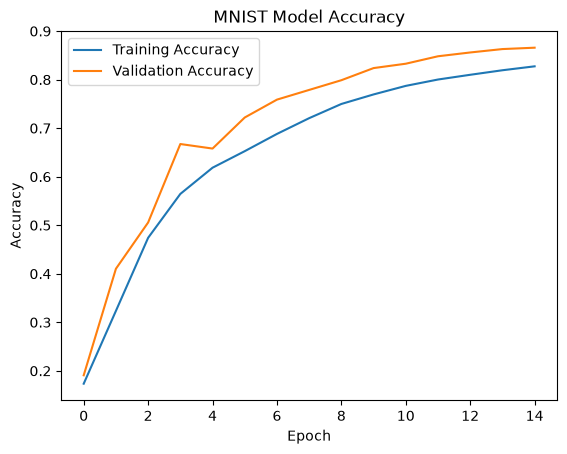

In [6]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical

import tensorflow as tf

# Load MNIST dataset
(trainX, trainY), (testX, testY) = tf.keras.datasets.mnist.load_data()

# Normalize and flatten images
trainX = trainX.reshape(-1, 784).astype("float32") / 255.0
testX = testX.reshape(-1, 784).astype("float32") / 255.0

# One-hot encode labels
trainY = to_categorical(trainY, 10)
testY = to_categorical(testY, 10)

# Create neural network
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(10, activation="softmax")
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train model
history = model.fit(
    trainX, trainY,
    epochs=15,
    batch_size=128,
    validation_split=0.1
)

# Evaluate model
loss, accuracy = model.evaluate(testX, testY)

print("\nMNIST Test Accuracy:", accuracy)

# Predictions
predictions = model.predict(testX)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(testY, axis=1)

print("\nClassification Report:")
print(classification_report(actual_labels, predicted_labels))

# Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("MNIST Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


### CIFER-10 (image classification) using TensorFlow/Keras

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.3230 - loss: 1.8975 - val_accuracy: 0.2702 - val_loss: 2.0382
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.3966 - loss: 1.7206 - val_accuracy: 0.2830 - val_loss: 2.0314
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.4220 - loss: 1.6439 - val_accuracy: 0.3176 - val_loss: 2.1233
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.4427 - loss: 1.5906 - val_accuracy: 0.3842 - val_loss: 1.7521
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.4561 - loss: 1.5506 - val_accuracy: 0.3614 - val_loss: 1.7401
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 45s 38ms/step - accuracy: 0.4672 - loss: 1.5142 - val_accuracy: 0.3102 - val_loss: 2.0325
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.4766 - loss: 1.4854 - val_accuracy: 0.4212 - val_loss: 1.6173
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.4877 - loss: 1.4561 - 

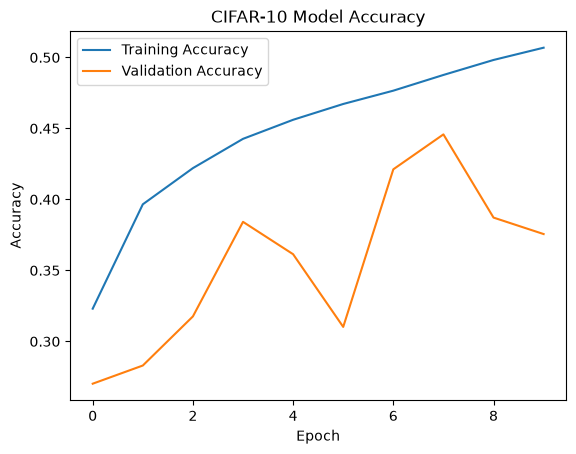

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Normalize image values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Convert labels into one-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Create neural network
model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(1024, activation="relu"),
    Dense(512, activation="relu"),
    Dense(10, activation="softmax")
])

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)

print("\nCIFAR-10 Test Accuracy:", accuracy)

# Predictions
predictions = model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

print("\nClassification Report:")
print(classification_report(actual_labels, predicted_labels))

# Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CIFAR-10 Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()